# Myocardial infarction — best ones

This notebook **loads saved results only**: it does not refit models, estimate rho,
or rerun experiments. The shortlist covers the broad early-stopping sweep, focused
Delta/optimizer sweep, initialization sensitivity, fine matched-L2 full solves, and
earlier numerically checked penalized/intercept experiments.

**Ranking:** among distinct configurations with two numerical checks, sort by the
mean total-variation (TV) distance of the conditional one-change posterior from the
archived conditional curve. Lower is better. TV is recomputed from saved probability
vectors on the full reference age support; probability excluded by a larger Delta
is not renormalized away. Duplicate configurations are removed, preferring the newer
checked implementation. There is **no P(1)>0.5 cutoff** and no hidden probability bonus.
This is a shape ranking, not a universal ranking of inferential quality.

**Preferences:** rows using an intercept or different penalties are explicitly
flagged. They remain in the overall shape ranking rather than being presented as
satisfying the no-intercept/matched-fit preference. A separate preferred subset is
shown at the end. Rank 3 is the leading current no-intercept compromise between
original-like shape and P(1) close to one-half; rank 2 is slightly closer in shape.

All probability ranges compare 512 Sobol draws/seed 42 with 1,024 draws/seed 123;
they are **not confidence intervals**. These same-data, outcome-inspected heuristic
analyses do not establish calibration or validate a selected model. In particular,
rho estimates can have nonzero moment-equation residuals, and the existing state
equations are only approximations for early-stopped/penalized coefficient fits.


In [1]:
"""Read-only experiment aggregation: rank saved, independently checked curves."""
from pathlib import Path
import json,pickle,hashlib
import numpy as np
import pandas as pd

BASE=Path('results/myocardial_finite_iteration_443c17cf2df6')
OLD=Path('results/myocardial_exploration_4026d0e775d2')
OFFSET=Path('results/myocardial_intercept_exploration_f53f59063391')


def curve_metrics(ages,curve,reference):
    ages=np.asarray(ages,float);curve=np.asarray(curve,float)
    assert len(ages)==len(curve) and len(set(ages))==len(ages)
    assert np.isfinite(curve).all() and np.min(curve)>=0
    np.testing.assert_allclose(curve.sum(),1.,atol=1e-8)
    mapping=dict(zip(ages,curve));support=set(reference)|set(mapping)
    return dict(TV=.5*sum(abs(reference.get(a,0.)-mapping.get(a,0.)) for a in support),
        above55=float(curve[ages>55].sum()),peak=float(ages[np.argmax(curve)]),
        max_probability=float(curve.max()))


def rank_candidates(rows):
    table=pd.DataFrame(rows).sort_values('priority',ascending=False,kind='stable')
    table=table.drop_duplicates('configuration').sort_values(['mean_TV','max_TV','configuration'],kind='stable').reset_index(drop=True)
    table.insert(0,'rank',np.arange(1,len(table)+1));return table


def load_candidates():
    from tools.myocardial_finite_iteration_exploration import load_data,reference_distribution
    reference=reference_distribution();_,_,ages,locations=load_data();all_ages=ages[locations]
    rows=[];curves={}
    def add(first,second,meta,first_path,second_path):
        a=np.asarray(first.get('ages',all_ages),float)
        b=np.asarray(second.get('ages',all_ages),float)
        np.testing.assert_array_equal(a,b)
        p=np.asarray(first['conditional']);q=np.asarray(second['conditional'])
        m=curve_metrics(a,p,reference);n=curve_metrics(a,q,reference)
        probabilities=[float(first['P_1']),float(second['P_1'])]
        assert min(probabilities)>=-1e-8 and max(probabilities)<=1+1e-8
        probabilities=np.clip(probabilities,0,1)
        key=json.dumps({k:meta[k] for k in ('auxiliary','posterior','intercept','Delta','rho_updates','initialization')},sort_keys=True)
        ident=hashlib.sha256((str(first_path)+'|'+str(second_path)).encode()).hexdigest()[:12]
        row=dict(meta,id=ident,configuration=key,P1_min=min(probabilities),P1_max=max(probabilities),
            mean_TV=(m['TV']+n['TV'])/2,max_TV=max(m['TV'],n['TV']),
            numerical_curve_TV=float(.5*np.abs(p-q).sum()),
            mass_above55_min=min(m['above55'],n['above55']),
            peak_min=min(m['peak'],n['peak']),peak_max=max(m['peak'],n['peak']),
            primary_P1=probabilities[0],check_P1=probabilities[1],
            moment_residual=float(first.get('moment_residual',meta.get('moment_residual',np.nan))),
            primary_checkpoint=str(first_path),check_checkpoint=str(second_path))
        rows.append(row);curves[ident]=dict(ages=a,primary=p,check=q)
    stage_dirs={'broad':BASE,'focused':BASE/'focus_354ed8f1e782',
        'initializations':BASE/'initializations_08d005a910b5',
        'fully_solved_matched_L2':BASE/'matched_l2_full_affdef22fb6c'}
    table=pd.read_csv(BASE/'combined_with_full_l2.csv')
    for row in table.itertuples():
        folder=stage_dirs[row.stage]
        if row.stage=='fully_solved_matched_L2':
            paths=[folder/(row.case+'_'+tag+'_score.pkl') for tag in ('q9_seed42','q10_seed123')]
            auxiliary=posterior=f'Logistic L2 {row.strength:.12g} (full solve)'
        else:
            paths=[folder/(row.case+'_'+row.posterior_fit+'_'+tag+'.pkl') for tag in ('q9_seed42','q10_seed123')]
            auxiliary='LS' if row.group=='least_squares' else f'Logistic {"L-BFGS" if str(row.auxiliary).startswith("lbfgs") else "FISTA"} {int(row.auxiliary_budget)} iterations'
            posterior=f'Logistic {"L-BFGS" if row.posterior_fit.startswith("lbfgs") else "FISTA"} {int(row.posterior_budget)} iterations'
        init=row.initialization if pd.notna(row.initialization) else 'identity'
        if init=='scale1_corr0':init='identity'
        add(*[pickle.load(p.open('rb')) for p in paths],dict(
            auxiliary=auxiliary,posterior=posterior,intercept=False,Delta=int(row.Delta),
            rho_updates=int(row.rho_updates),initialization=init,stage=row.stage,priority=3,
            preference_note='No intercept; LS auxiliary' if row.group=='least_squares' else ('No intercept; matched' if row.group in ('logistic_matched','fully_solved_matched_L2') else 'No intercept; different fitting budgets')),*paths)
    # Earlier LS-auxiliary penalty sweeps, retaining every independently checked pair.
    folder=OLD/'denser_penalty_grid'
    for second_path in sorted(folder.glob('*_independent.pkl')):
        first_path=second_path.with_name(second_path.name.replace('_independent.pkl','.pkl'))
        first=pickle.load(first_path.open('rb'));second=pickle.load(second_path.open('rb'))
        case=second['case'];base=pickle.load((OLD/(case+'.pkl')).open('rb'))
        assert base['scenario']['auxiliary']=='least_squares'
        add(first,second,dict(auxiliary='LS',posterior=f'Logistic {first["penalty"].upper()} {first["strength"]:.12g} (full solve)',
            intercept=False,Delta=1,rho_updates=int(base['scenario']['iteration']),initialization='identity',
            stage='earlier_LS_penalty',priority=2,preference_note='No intercept; LS auxiliary',
            moment_residual=base['scenario']['moment_residual']),first_path,second_path)
    # Earlier intercept-aware fits: explicitly flag preference violations, never
    # silently reclassify them as no-intercept or matched-penalty candidates.
    folder=OFFSET/'penalty_resolution'
    for first_path in sorted(folder.glob('*_seed42_q9.pkl')):
        second_path=first_path.with_name(first_path.name.replace('_seed42_q9.pkl','_seed123_q10.pkl'))
        if not second_path.exists():continue
        first=pickle.load(first_path.open('rb'));second=pickle.load(second_path.open('rb'))
        rec=pickle.load((OFFSET/(first['case']+'.pkl')).open('rb'));aux=rec['scenario']['auxiliary']
        if aux=='least_squares':auxiliary='LS';note='Uses intercept'
        else:
            family,strength=aux.split('_',1);strength=float(strength)
            auxiliary=f'Logistic {family.upper()} {strength:.12g} (full solve)'
            note='Uses intercept; '+('matched penalties' if family==first['penalty'] and strength==first['strength'] else 'mismatched penalties')
        add(first,second,dict(auxiliary=auxiliary,posterior=f'Logistic {first["penalty"].upper()} {first["strength"]:.12g} (full solve)',
            intercept=True,Delta=1,rho_updates=int(rec['scenario']['iteration']),initialization='identity',
            stage='earlier_intercept',priority=2,preference_note=note),first_path,second_path)
    # Earlier exact-match checks (not all will be competitive on shape).
    folder=OLD/'exact_matching_no_intercept'
    for second_path in sorted(folder.glob('*_independent_score.pkl')):
        first_path=second_path.with_name(second_path.name.replace('_independent_score.pkl','_score.pkl'))
        first=pickle.load(first_path.open('rb'));second=pickle.load(second_path.open('rb'))
        name=f'Logistic {first["penalty"].upper()} {first["strength"]:.12g} (full solve)'
        add(first,second,dict(auxiliary=name,posterior=name,intercept=False,Delta=1,rho_updates=int(first['iteration']),
            initialization='identity',stage='earlier_exact_match',priority=1,preference_note='No intercept; matched penalties'),first_path,second_path)
    ranked=rank_candidates(rows)
    return ranked,curves,reference


def summary_table(ranked):
    result=ranked[['rank','auxiliary','posterior','intercept','Delta','rho_updates']].copy()
    result['P(1) numerical range']=[f'{lo:.3f}–{hi:.3f}' for lo,hi in zip(ranked.P1_min,ranked.P1_max)]
    result['Conditional mode (age)']=[f'{lo:g}' if lo==hi else f'{lo:g}–{hi:g}' for lo,hi in zip(ranked.peak_min,ranked.peak_max)]
    result['Mean TV']=ranked.mean_TV.round(3)
    result['Numerical curve TV']=ranked.numerical_curve_TV.round(3)
    result['Min. mass above 55']=ranked.mass_above55_min.round(3)
    result['Preference notes']=ranked.preference_note
    return result


In [2]:
ranked,curves,reference=load_candidates()
best=ranked.head(10).copy()
assert len(best)==10
print(f'Ranked {len(ranked)} distinct configurations with two saved numerical checks.')
display(summary_table(best))
report_digest=hashlib.sha256(Path('tools/myocardial_best_ones.py').read_bytes()).hexdigest()[:12]
report_root=Path('results')/('myocardial_best_ones_'+report_digest)
report_root.mkdir(exist_ok=True)
ranked.to_csv(report_root/'all_checked_candidates.csv',index=False)
best.to_csv(report_root/'top_ten.csv',index=False)
print('Auditable ranking and exact checkpoint paths:',report_root)


/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ranked 153 distinct configurations with two saved numerical checks.


,rank,auxiliary,posterior,intercept,Delta,rho_updates,P(1) numerical range,Conditional mode (age),Mean TV,Numerical curve TV,Min. mass above 55,Preference notes
0,1,LS,Logistic FISTA 16 iterations,False,5,24,0.261–0.266,81,0.169,0.031,0.900,No intercept; LS auxiliary
1,2,LS,Logistic FISTA 12 iterations,False,2,20,0.430–0.437,80,0.176,0.024,0.935,No intercept; LS auxiliary
2,3,LS,Logistic FISTA 16 iterations,False,2,20,0.464–0.483,81,0.217,0.031,0.958,No intercept; LS auxiliary
3,4,LS,Logistic L1 0.0001 (full solve),False,1,30,0.402–0.453,79,0.245,0.053,0.787,No intercept; LS auxiliary
4,5,LS,Logistic L-BFGS 5 iterations,False,5,20,0.206–0.215,84,0.249,0.062,0.901,No intercept; LS auxiliary
5,6,LS,Logistic L-BFGS 5 iterations,False,10,20,0.202–0.206,83,0.266,0.034,0.948,No intercept; LS auxiliary
6,7,Logistic L1 0.0001 (full solve),Logistic L2 1.5e-06 (full solve),True,1,30,0.718–0.747,81,0.291,0.036,1.000,Uses intercept; mismatched penalties
7,8,Logistic L1 0.0001 (full solve),Logistic L2 1.2e-06 (full solve),True,1,30,0.602–0.631,81,0.298,0.034,1.000,Uses intercept; mismatched penalties
8,9,LS,Logistic L-BFGS 5 iterations,False,2,16,0.306–0.316,84,0.305,0.066,0.922,No intercept; LS auxiliary
9,10,Logistic L1 0.0001 (full solve),Logistic L2 1e-06 (full solve),True,1,10,0.846–0.850,81,0.344,0.010,1.000,Uses intercept; mismatched penalties


Auditable ranking and exact checkpoint paths: results/myocardial_best_ones_2e6d60998999


Top ten conditional posteriors: common axes; zero mass shown outside each candidate support


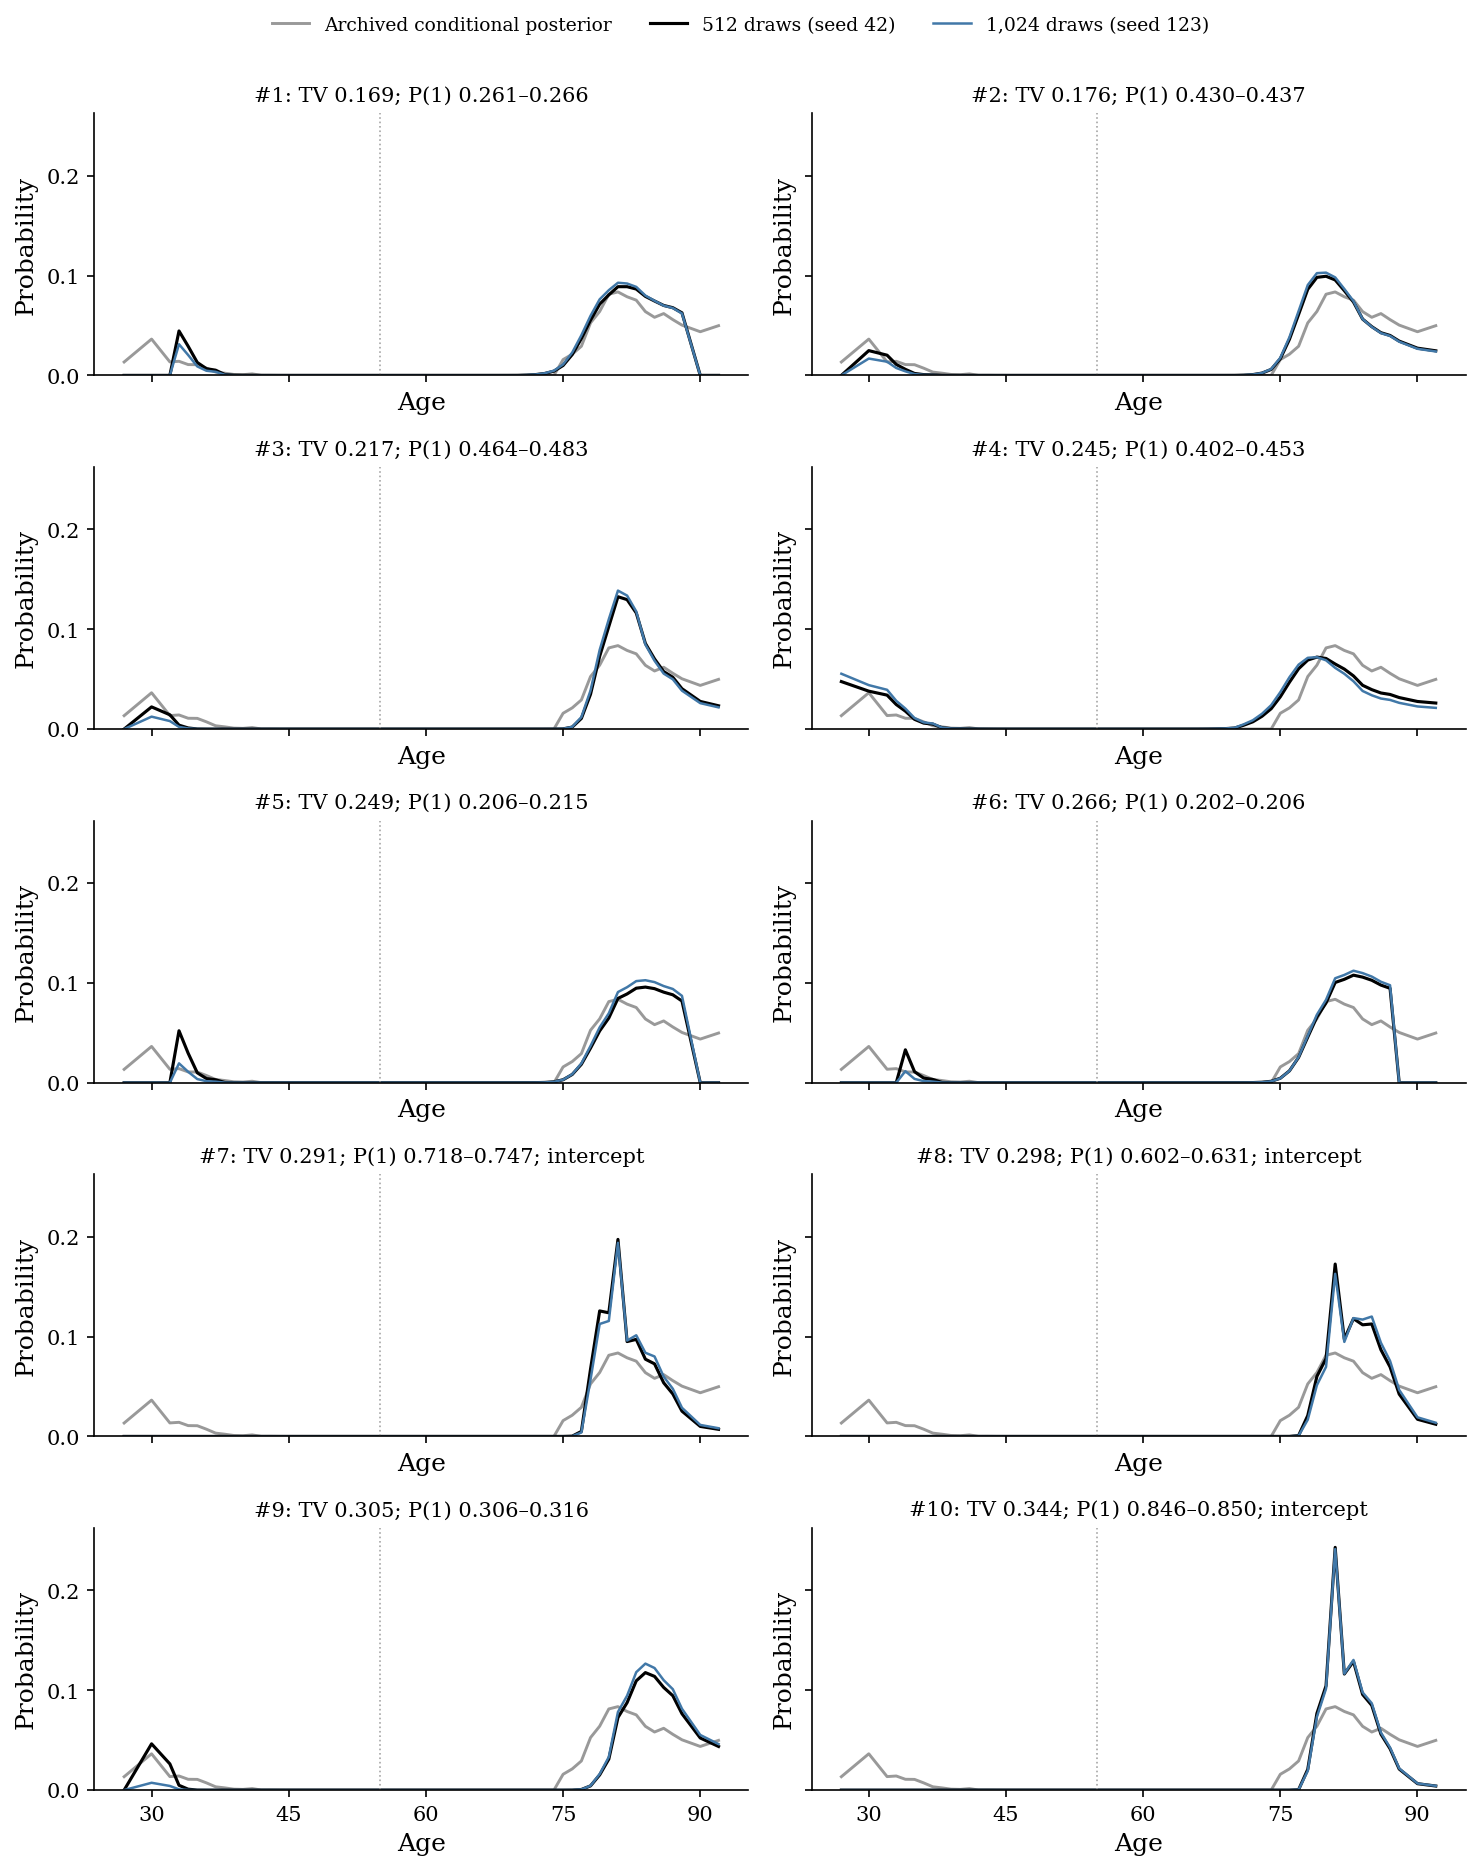

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'axes.labelsize':12,'xtick.labelsize':10,'ytick.labelsize':10,'legend.fontsize':9,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
a=np.array(sorted(reference));p=np.array([reference[x] for x in a])
def aligned(record,key):
    mapping=dict(zip(record['ages'],record[key]))
    return np.array([mapping.get(x,0.) for x in a])
def draw_curves(ax,row,legend=False):
    saved=curves[row.id]
    ax.plot(a,p,color='0.60',lw=1.4,label='Archived conditional posterior')
    ax.plot(a,aligned(saved,'primary'),color='black',lw=1.5,label='512 draws (seed 42)')
    ax.plot(a,aligned(saved,'check'),color='#4178a8',lw=1.2,label='1,024 draws (seed 123)')
    ax.axvline(55,color='0.65',ls=':',lw=.8)
    ax.xaxis.set_major_locator(MaxNLocator(5,integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.set_xlabel('Age');ax.set_ylabel('Probability')
    if legend:ax.legend(frameon=False,fontsize=8)
print('Top ten conditional posteriors: common axes; zero mass shown outside each candidate support')
fig,axes=plt.subplots(5,2,figsize=(10,12.5),sharex=True,sharey=True)
upper=1.08*max([p.max()]+[max(curves[row.id]['primary'].max(),curves[row.id]['check'].max()) for row in best.itertuples()])
for ax,row in zip(axes.flat,best.itertuples()):
    draw_curves(ax,row)
    flag='; intercept' if row.intercept else ''
    ax.set_title(f'#{row.rank}: TV {row.mean_TV:.3f}; P(1) {row.P1_min:.3f}–{row.P1_max:.3f}{flag}',fontsize=10)
    ax.set_ylim(0,upper)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=3,frameon=False,fontsize=9)
fig.tight_layout(rect=(0,0,1,.97));plt.show()


Count probability across numerical checks (connecting lines are not confidence intervals)


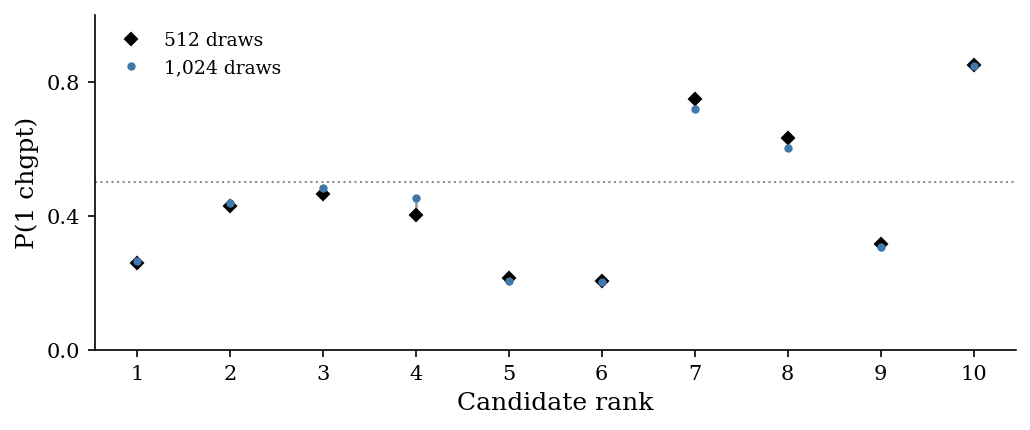

Shape/probability trade-off: rank numbers identify the configurations above


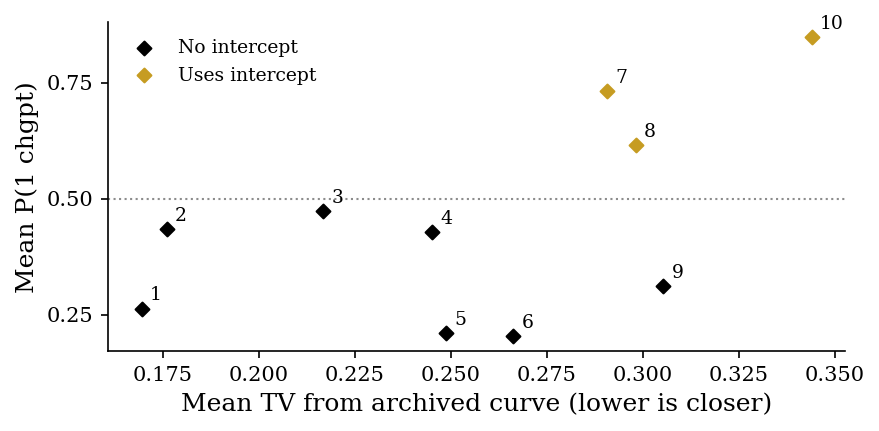

In [4]:
print('Count probability across numerical checks (connecting lines are not confidence intervals)')
fig,ax=plt.subplots(figsize=(7,3))
for row in best.itertuples():
    ax.plot([row.rank,row.rank],[row.P1_min,row.P1_max],color='0.6',lw=1.2)
ax.plot(best['rank'],best.primary_P1,'D',color='black',ms=4,label='512 draws')
ax.plot(best['rank'],best.check_P1,'o',color='#4178a8',ms=3,label='1,024 draws')
ax.axhline(.5,color='0.55',ls=':',lw=1)
ax.set_xticks(best['rank']);ax.set_xlabel('Candidate rank');ax.set_ylabel('P(1 chgpt)')
ax.set_ylim(0,1);ax.yaxis.set_major_locator(MaxNLocator(3));ax.legend(frameon=False)
fig.tight_layout();plt.show()

print('Shape/probability trade-off: rank numbers identify the configurations above')
fig,ax=plt.subplots(figsize=(6,3))
for row in best.itertuples():
    color='#c69c22' if row.intercept else 'black'
    mean_p=(row.P1_min+row.P1_max)/2
    ax.scatter(row.mean_TV,mean_p,color=color,marker='D',s=22)
    ax.annotate(str(row.rank),(row.mean_TV,mean_p),xytext=(4,4),textcoords='offset points',fontsize=9)
ax.axhline(.5,color='0.55',ls=':',lw=1)
ax.set_xlabel('Mean TV from archived curve (lower is closer)');ax.set_ylabel('Mean P(1 chgpt)')
ax.scatter([],[],color='black',marker='D',s=22,label='No intercept')
ax.scatter([],[],color='#c69c22',marker='D',s=22,label='Uses intercept')
ax.legend(frameon=False);ax.yaxis.set_major_locator(MaxNLocator(3))
fig.tight_layout();plt.show()


Individual plots and exact configurations
#1: auxiliary = LS; posterior-input fit = Logistic FISTA 16 iterations.
Intercept = False; Delta = 5; rho updates = 24; rho initialization = identity. No intercept; LS auxiliary.
P(1) = 0.260890–0.265568; mean reference TV = 0.169467; TV between numerical checks = 0.031304; minimum mass above 55 = 0.9002; moment residual = 0.0129682.
Reference mass retained by this admissible age grid: 0.8433.


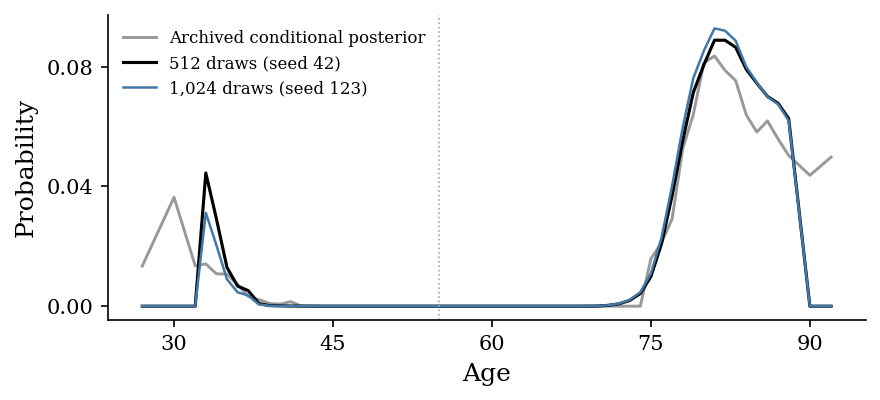

#2: auxiliary = LS; posterior-input fit = Logistic FISTA 12 iterations.
Intercept = False; Delta = 2; rho updates = 20; rho initialization = identity. No intercept; LS auxiliary.
P(1) = 0.430037–0.437390; mean reference TV = 0.175996; TV between numerical checks = 0.024246; minimum mass above 55 = 0.9346; moment residual = 0.0131663.
Reference mass retained by this admissible age grid: 0.9866.


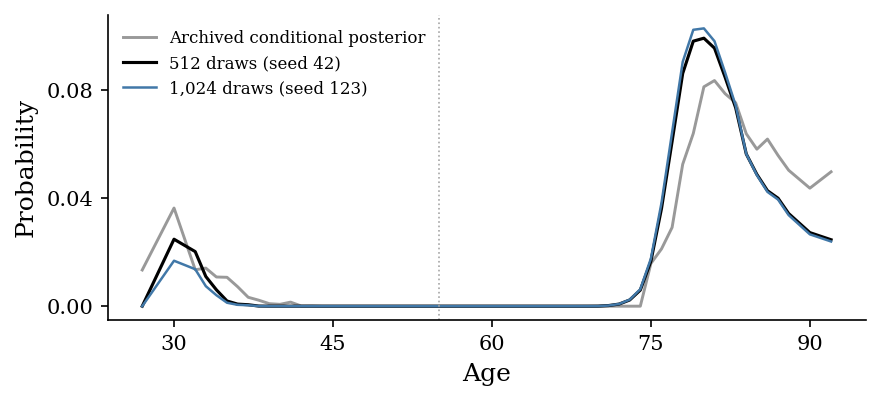

#3: auxiliary = LS; posterior-input fit = Logistic FISTA 16 iterations.
Intercept = False; Delta = 2; rho updates = 20; rho initialization = identity. No intercept; LS auxiliary.
P(1) = 0.463740–0.482719; mean reference TV = 0.216686; TV between numerical checks = 0.030629; minimum mass above 55 = 0.9584; moment residual = 0.0131663.
Reference mass retained by this admissible age grid: 0.9866.


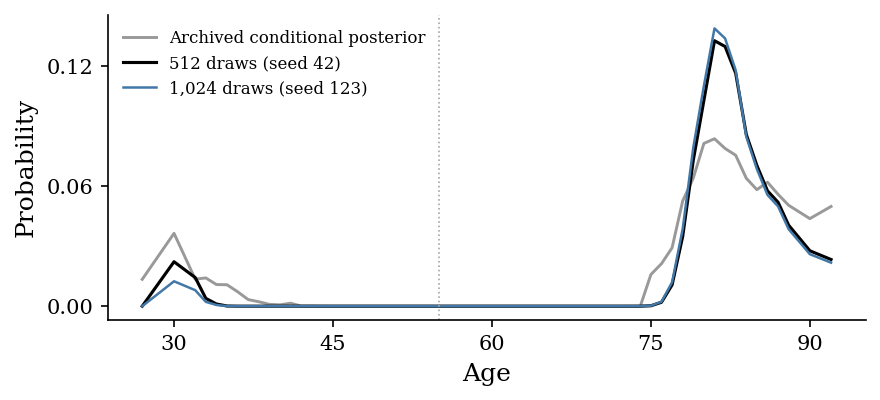

#4: auxiliary = LS; posterior-input fit = Logistic L1 0.0001 (full solve).
Intercept = False; Delta = 1; rho updates = 30; rho initialization = identity. No intercept; LS auxiliary.
P(1) = 0.401621–0.453420; mean reference TV = 0.245095; TV between numerical checks = 0.053327; minimum mass above 55 = 0.7868; moment residual = 0.0130435.
Reference mass retained by this admissible age grid: 1.0000.


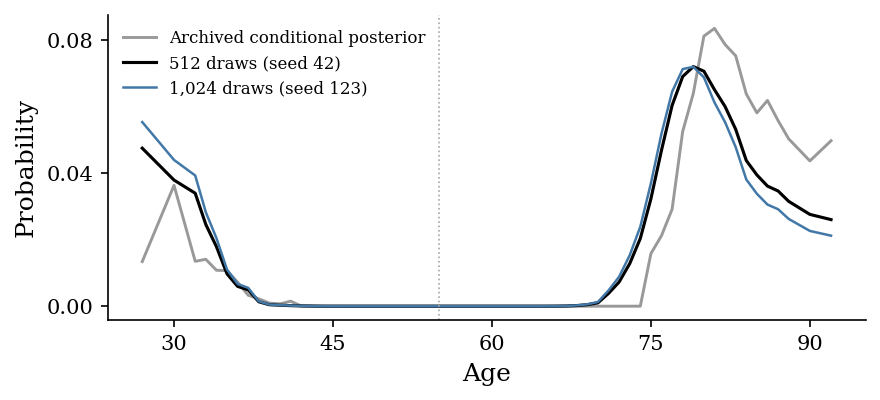

#5: auxiliary = LS; posterior-input fit = Logistic L-BFGS 5 iterations.
Intercept = False; Delta = 5; rho updates = 20; rho initialization = identity. No intercept; LS auxiliary.
P(1) = 0.205679–0.214709; mean reference TV = 0.248653; TV between numerical checks = 0.062323; minimum mass above 55 = 0.9010; moment residual = 0.0130999.
Reference mass retained by this admissible age grid: 0.8433.


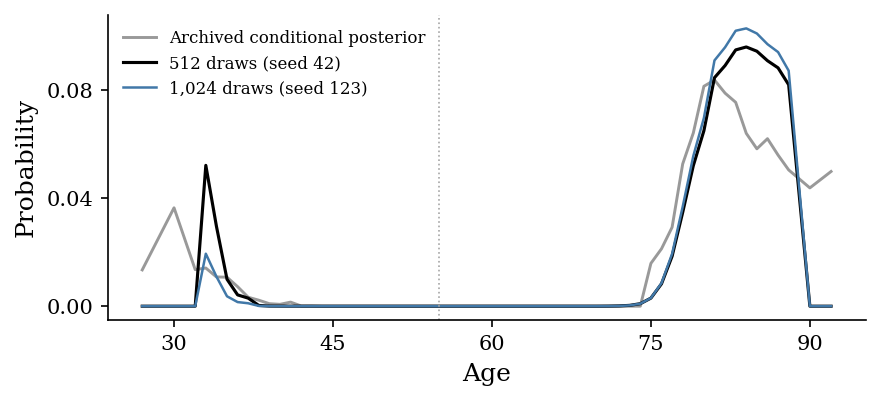

#6: auxiliary = LS; posterior-input fit = Logistic L-BFGS 5 iterations.
Intercept = False; Delta = 10; rho updates = 20; rho initialization = identity. No intercept; LS auxiliary.
P(1) = 0.201833–0.205649; mean reference TV = 0.266246; TV between numerical checks = 0.034275; minimum mass above 55 = 0.9477; moment residual = 0.0130678.
Reference mass retained by this admissible age grid: 0.7788.


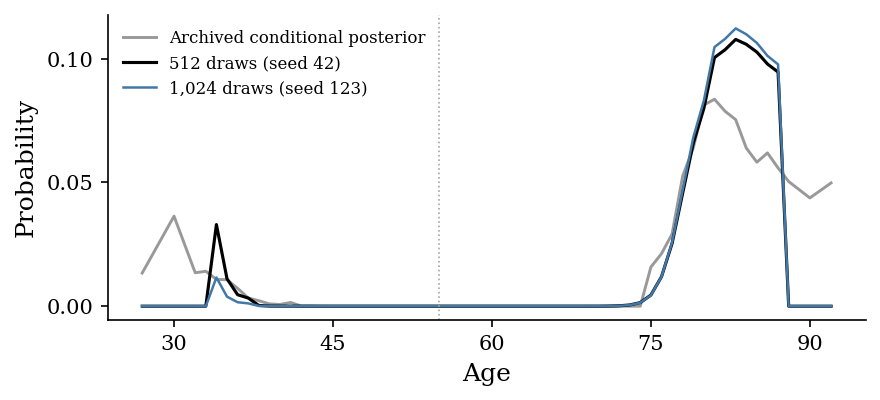

#7: auxiliary = Logistic L1 0.0001 (full solve); posterior-input fit = Logistic L2 1.5e-06 (full solve).
Intercept = True; Delta = 1; rho updates = 30; rho initialization = identity. Uses intercept; mismatched penalties.
P(1) = 0.717686–0.747208; mean reference TV = 0.290673; TV between numerical checks = 0.036285; minimum mass above 55 = 1.0000; moment residual = 0.113503.
Reference mass retained by this admissible age grid: 1.0000.


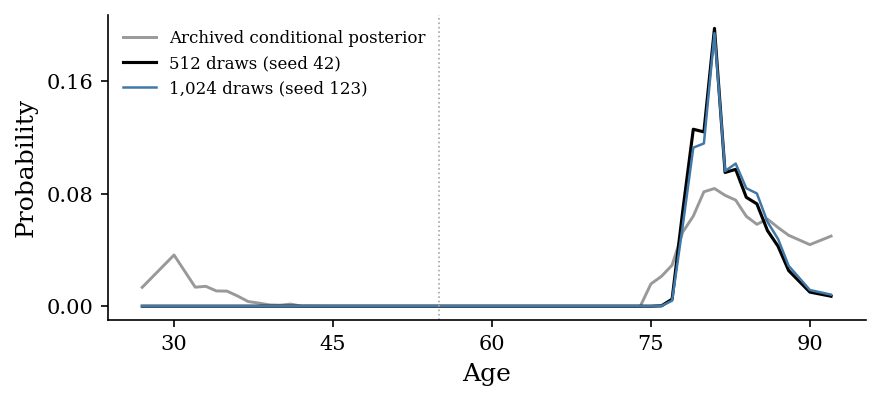

#8: auxiliary = Logistic L1 0.0001 (full solve); posterior-input fit = Logistic L2 1.2e-06 (full solve).
Intercept = True; Delta = 1; rho updates = 30; rho initialization = identity. Uses intercept; mismatched penalties.
P(1) = 0.602106–0.630825; mean reference TV = 0.298115; TV between numerical checks = 0.033937; minimum mass above 55 = 1.0000; moment residual = 0.113503.
Reference mass retained by this admissible age grid: 1.0000.


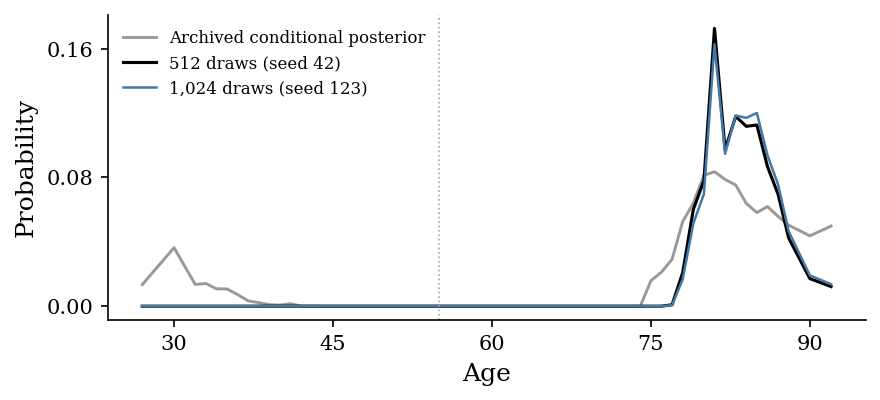

#9: auxiliary = LS; posterior-input fit = Logistic L-BFGS 5 iterations.
Intercept = False; Delta = 2; rho updates = 16; rho initialization = identity. No intercept; LS auxiliary.
P(1) = 0.305700–0.316399; mean reference TV = 0.305304; TV between numerical checks = 0.065917; minimum mass above 55 = 0.9217; moment residual = 0.0135828.
Reference mass retained by this admissible age grid: 0.9866.


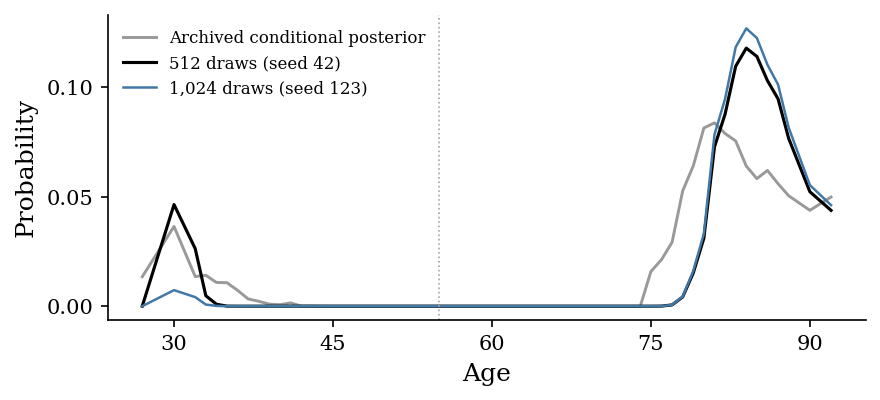

#10: auxiliary = Logistic L1 0.0001 (full solve); posterior-input fit = Logistic L2 1e-06 (full solve).
Intercept = True; Delta = 1; rho updates = 10; rho initialization = identity. Uses intercept; mismatched penalties.
P(1) = 0.845819–0.850393; mean reference TV = 0.343959; TV between numerical checks = 0.009604; minimum mass above 55 = 1.0000; moment residual = 0.157522.
Reference mass retained by this admissible age grid: 1.0000.


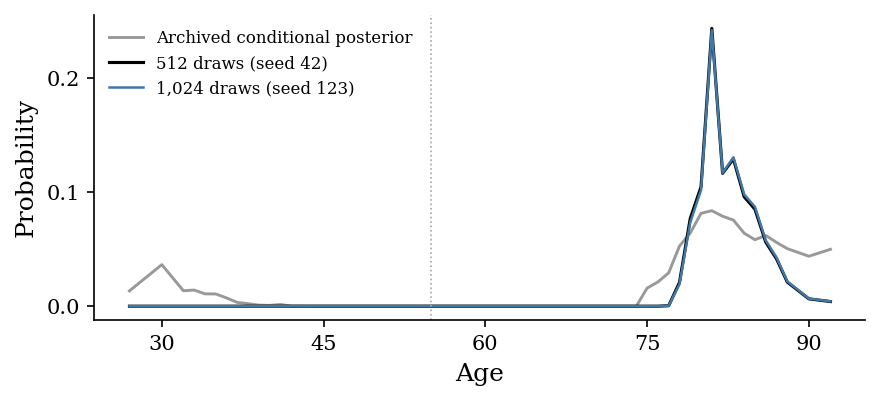

In [5]:
print('Individual plots and exact configurations')
for row in best.itertuples():
    print(f'#{row.rank}: auxiliary = {row.auxiliary}; posterior-input fit = {row.posterior}.')
    print(f'Intercept = {row.intercept}; Delta = {row.Delta}; rho updates = {row.rho_updates}; '
          f'rho initialization = {row.initialization}. {row.preference_note}.')
    print(f'P(1) = {row.P1_min:.6f}–{row.P1_max:.6f}; mean reference TV = {row.mean_TV:.6f}; '
          f'TV between numerical checks = {row.numerical_curve_TV:.6f}; '
          f'minimum mass above 55 = {row.mass_above55_min:.4f}; '
          f'moment residual = {row.moment_residual:.6g}.')
    retained=sum(reference.get(x,0.) for x in curves[row.id]['ages'])
    print(f'Reference mass retained by this admissible age grid: {retained:.4f}.')
    fig,ax=plt.subplots(figsize=(6,2.8));draw_curves(ax,row,legend=True)
    fig.tight_layout();plt.show()


In [6]:
print('Top-ten candidates satisfying the no-intercept preference')
display(summary_table(best[~best.intercept]))
print('For a shape/probability compromise inspect #3 first, then #2.')
print('For shape alone inspect #1; its count probability is substantially below one-half.')
print('Candidates #7, #8, #10 use intercepts and mismatched penalties; they are historical alternatives, not preference-compliant recommendations.')
print('No matched logistic/logistic candidate ranks in this overall shape-based top ten.')
print('Exact input checkpoints and nonzero moment-equation residuals:')
display(best[['rank','moment_residual','primary_checkpoint','check_checkpoint']])


Top-ten candidates satisfying the no-intercept preference


,rank,auxiliary,posterior,intercept,Delta,rho_updates,P(1) numerical range,Conditional mode (age),Mean TV,Numerical curve TV,Min. mass above 55,Preference notes
0,1,LS,Logistic FISTA 16 iterations,False,5,24,0.261–0.266,81,0.169,0.031,0.900,No intercept; LS auxiliary
1,2,LS,Logistic FISTA 12 iterations,False,2,20,0.430–0.437,80,0.176,0.024,0.935,No intercept; LS auxiliary
2,3,LS,Logistic FISTA 16 iterations,False,2,20,0.464–0.483,81,0.217,0.031,0.958,No intercept; LS auxiliary
3,4,LS,Logistic L1 0.0001 (full solve),False,1,30,0.402–0.453,79,0.245,0.053,0.787,No intercept; LS auxiliary
4,5,LS,Logistic L-BFGS 5 iterations,False,5,20,0.206–0.215,84,0.249,0.062,0.901,No intercept; LS auxiliary
5,6,LS,Logistic L-BFGS 5 iterations,False,10,20,0.202–0.206,83,0.266,0.034,0.948,No intercept; LS auxiliary
8,9,LS,Logistic L-BFGS 5 iterations,False,2,16,0.306–0.316,84,0.305,0.066,0.922,No intercept; LS auxiliary


For a shape/probability compromise inspect #3 first, then #2.
For shape alone inspect #1; its count probability is substantially below one-half.
Candidates #7, #8, #10 use intercepts and mismatched penalties; they are historical alternatives, not preference-compliant recommendations.
No matched logistic/logistic candidate ranks in this overall shape-based top ten.
Exact input checkpoints and nonzero moment-equation residuals:


,rank,moment_residual,primary_checkpoint,check_checkpoint
0,1,0.012968,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
1,2,0.013166,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
2,3,0.013166,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
3,4,0.013044,results/myocardial_exploration_4026d0e775d2/de...,results/myocardial_exploration_4026d0e775d2/de...
4,5,0.013100,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
5,6,0.013068,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
6,7,0.113503,results/myocardial_intercept_exploration_f53f5...,results/myocardial_intercept_exploration_f53f5...
7,8,0.113503,results/myocardial_intercept_exploration_f53f5...,results/myocardial_intercept_exploration_f53f5...
8,9,0.013583,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
9,10,0.157522,results/myocardial_intercept_exploration_f53f5...,results/myocardial_intercept_exploration_f53f5...
